# RQ1 — Chunking and Retrieval Evaluation

This notebook runs and analyzes **Research Question 1**: which combination of chunking strategy, chunk size, and retrieval method yields the best retrieval quality for ESRS disclosure queries?

**Experimental design** — full 3 x 3 x 6 factorial:

| Factor | Levels |
|---|---|
| Chunking strategy | `fixed`, `structure_aware`, `semantic` |
| Chunk size (tokens) | 256, 512, 1024 |
| Retrieval method | `dense`, `dense_rerank`, `sparse`, `sparse_rerank`, `hybrid_rrf`, `hybrid_rerank` |

**Total: 54 configurations**, each evaluated against the Golden Standard.

**Evaluation coverage**: 85 of 204 question-company pairs are retrieval-evaluable (5 ESRS standards with annotated evidence passages: ESRS 1, 2, E1, S1, G1). The remaining 119 pairs have empty evidence text in the current golden standard and are excluded from metric computation.

**Primary metric**: Recall@15 — the fraction of gold evidence passages retrieved in the top-15 chunks.

## 1. Environment and Imports

In [1]:
import sys
from pathlib import Path

PROJECT_ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
if str(PROJECT_ROOT) not in sys.path:
    sys.path.insert(0, str(PROJECT_ROOT))

import json
import pandas as pd
import matplotlib.pyplot as plt

from rag.config.settings import RQ1_RESULTS_DIR, build_rq1_experiment_grid
from rag.pipeline.rq1_runner import RQ1PipelineRunner

print(f"Project root: {PROJECT_ROOT}")
print(f"RQ1 result directory: {RQ1_RESULTS_DIR}")

Project root: /Users/sinahaghgoo/Library/CloudStorage/OneDrive-Persönlich/Master Thesis/Thesis Coding Part/ESRS-Regulation-Bot
RQ1 result directory: /Users/sinahaghgoo/Library/CloudStorage/OneDrive-Persönlich/Master Thesis/Thesis Coding Part/ESRS-Regulation-Bot/data/artifacts/evaluation_results/rq1


## 2. Experiment Grid

The full factorial grid produces 54 configurations. Each row represents one pipeline configuration that will be evaluated independently.

In [2]:
grid = build_rq1_experiment_grid()
print(f"Total configs: {len(grid)}")

grid_df = pd.DataFrame([
    {"config_id": c.config_id, "chunk_strategy": c.chunk_strategy,
     "chunk_size": c.chunk_size, "retrieval_method": c.retrieval_method}
    for c in grid
])
grid_df

Total configs: 54


,config_id,chunk_strategy,chunk_size,retrieval_method
0,fixed_256_dense,fixed,256,dense
1,fixed_256_dense_rerank,fixed,256,dense_rerank
2,fixed_256_sparse,fixed,256,sparse
3,fixed_256_sparse_rerank,fixed,256,sparse_rerank
4,fixed_256_hybrid_rrf,fixed,256,hybrid_rrf
5,fixed_256_hybrid_rerank,fixed,256,hybrid_rerank
6,fixed_512_dense,fixed,512,dense
7,fixed_512_dense_rerank,fixed,512,dense_rerank
8,fixed_512_sparse,fixed,512,sparse
9,fixed_512_sparse_rerank,fixed,512,sparse_rerank


## 3. Execute the RQ1 Evaluation Pipeline

`RQ1PipelineRunner.run()` iterates over all 54 configurations. For each one it:

1. Builds chunks for the strategy/size pair (cached across retrieval methods).
2. Embeds chunks and indexes them in Qdrant.
3. Retrieves top-15 chunks per golden-standard sample using the configured retrieval method.
4. Computes Recall@k, Precision@k, nDCG@10, MRR@10, and Budgeted Recall@4096.

Results are persisted incrementally so interrupted runs can resume. Set `DRY_RUN = True` to test with one configuration only.

In [3]:
DRY_RUN = False

runner = RQ1PipelineRunner(dry_run=DRY_RUN)
summary = runner.run()
summary

/Users/sinahaghgoo/Library/CloudStorage/OneDrive-Persönlich/Master Thesis/Thesis Coding Part/ESRS-Regulation-Bot/rag/indexing/qdrant_index.py:19: UserWarning: Local mode is not recommended for collections with more than 20,000 points. Collection <rq1_esrs_semantic_256> contains 32426 points. Consider using Qdrant in Docker or Qdrant Cloud for better performance with large datasets.
  self.client = QdrantClient(path=str(QDRANT_STORAGE_PATH))
/Users/sinahaghgoo/Library/CloudStorage/OneDrive-Persönlich/Master Thesis/Thesis Coding Part/ESRS-Regulation-Bot/rag/indexing/qdrant_index.py:19: UserWarning: Local mode is not recommended for collections with more than 20,000 points. Collection <rq1_esrs_semantic_512> contains 30149 points. Consider using Qdrant in Docker or Qdrant Cloud for better performance with large datasets.
  self.client = QdrantClient(path=str(QDRANT_STORAGE_PATH))
/Users/sinahaghgoo/Library/CloudStorage/OneDrive-Persönlich/Master Thesis/Thesis Coding Part/ESRS-Regulatio

Running config: fixed_256_dense
  -> completed: recall@15 = 0.0858
Running config: fixed_256_dense_rerank
  -> completed: recall@15 = 0.0858
Running config: fixed_256_sparse
  -> completed: recall@15 = 0.7596
Running config: fixed_256_sparse_rerank
  -> completed: recall@15 = 0.7596
Running config: fixed_256_hybrid_rrf
  -> completed: recall@15 = 0.6345
Running config: fixed_256_hybrid_rerank
  -> completed: recall@15 = 0.6279
Running config: fixed_512_dense
  -> completed: recall@15 = 0.2293
Running config: fixed_512_dense_rerank
  -> completed: recall@15 = 0.2293
Running config: fixed_512_sparse
  -> completed: recall@15 = 0.8946
Running config: fixed_512_sparse_rerank
  -> completed: recall@15 = 0.8946
Running config: fixed_512_hybrid_rrf
  -> completed: recall@15 = 0.7980
Running config: fixed_512_hybrid_rerank
  -> completed: recall@15 = 0.7355
Running config: fixed_1024_dense
  -> completed: recall@15 = 0.4005
Running config: fixed_1024_dense_rerank
  -> completed: recall@15 = 0.

Loading weights:   0%|          | 0/103 [00:00<?, ?it/s]

BertModel LOAD REPORT from: sentence-transformers/all-MiniLM-L6-v2
Key                     | Status     |  | 
------------------------+------------+--+-
embeddings.position_ids | UNEXPECTED |  | 

Notes:
- UNEXPECTED	:can be ignored when loading from different task/architecture; not ok if you expect identical arch.
/Users/sinahaghgoo/Library/CloudStorage/OneDrive-Persönlich/Master Thesis/Thesis Coding Part/ESRS-Regulation-Bot/rag/indexing/qdrant_index.py:77: UserWarning: Local mode is not recommended for collections with more than 20,000 points. Current collection contains 32426 points. Consider using Qdrant in Docker or Qdrant Cloud for better performance with large datasets.
  self.client.upsert(collection_name=collection_name, points=points, wait=True)


  -> completed: recall@15 = 0.1025
Running config: semantic_256_dense_rerank
  -> completed: recall@15 = 0.1025
Running config: semantic_256_sparse
  -> completed: recall@15 = 0.4793
Running config: semantic_256_sparse_rerank
  -> completed: recall@15 = 0.4793
Running config: semantic_256_hybrid_rrf
  -> completed: recall@15 = 0.3889
Running config: semantic_256_hybrid_rerank
  -> completed: recall@15 = 0.3844
Running config: semantic_512_dense
  -> completed: recall@15 = 0.1107
Running config: semantic_512_dense_rerank
  -> completed: recall@15 = 0.1107
Running config: semantic_512_sparse
  -> completed: recall@15 = 0.5220
Running config: semantic_512_sparse_rerank
  -> completed: recall@15 = 0.5220
Running config: semantic_512_hybrid_rrf
  -> completed: recall@15 = 0.4346
Running config: semantic_512_hybrid_rerank
  -> completed: recall@15 = 0.4269
Running config: semantic_1024_dense
  -> completed: recall@15 = 0.1078
Running config: semantic_1024_dense_rerank
  -> completed: recall@

{'winner': 'fixed_1024_sparse',
 'winner_metrics': {'recall@5': 0.8687091503267974,
  'recall@10': 0.923202614379085,
  'recall@15': 0.948937908496732,
  'precision@5': 0.669607843137255,
  'precision@10': 0.578921568627451,
  'precision@15': 0.526797385620915,
  'ndcg@10': 0.7901577278903814,
  'mrr@10': 0.8813783846872082,
  'budgeted_recall@4096': 0.8670751633986928},
 'evaluated_configs': 54}

## 4. Load Persisted Results

The pipeline writes `rq1_config_results.csv` and `.json` after each completed configuration. We reload the CSV here so the analysis cells below work independently of whether the pipeline was just executed or results were loaded from a previous run.

In [4]:
results_csv = RQ1_RESULTS_DIR / "rq1_config_results.csv"

df = pd.read_csv(results_csv)
print(f"Loaded {len(df)} configuration results")
df.sort_values("recall@15", ascending=False).head(10)

Loaded 54 configuration results


,config_id,chunk_strategy,chunk_size,retrieval_method,recall@5,recall@10,recall@15,precision@5,precision@10,precision@15,ndcg@10,mrr@10,budgeted_recall@4096
0,fixed_1024_sparse,fixed,1024,sparse,0.868709,0.923203,0.948938,0.669608,0.578922,0.526797,0.790158,0.881378,0.867075
1,fixed_1024_sparse_rerank,fixed,1024,sparse_rerank,0.868709,0.923203,0.948938,0.669608,0.578922,0.526797,0.790158,0.881378,0.867075
2,structure_aware_1024_sparse,structure_aware,1024,sparse,0.794363,0.878268,0.919526,0.543137,0.439706,0.396078,0.716769,0.815470,0.831699
3,structure_aware_1024_sparse_rerank,structure_aware,1024,sparse_rerank,0.794363,0.878268,0.919526,0.543137,0.439706,0.396078,0.716769,0.815470,0.831699
4,fixed_512_sparse,fixed,512,sparse,0.755147,0.857843,0.894608,0.544118,0.450000,0.393464,0.703399,0.773969,0.827451
5,fixed_512_sparse_rerank,fixed,512,sparse_rerank,0.755147,0.857843,0.894608,0.544118,0.450000,0.393464,0.703399,0.773969,0.827451
6,structure_aware_512_sparse,structure_aware,512,sparse,0.730392,0.841503,0.889297,0.491176,0.385294,0.327451,0.692009,0.752328,0.846405
7,structure_aware_512_sparse_rerank,structure_aware,512,sparse_rerank,0.730392,0.841503,0.889297,0.491176,0.385294,0.327451,0.692009,0.752328,0.846405
8,fixed_1024_hybrid_rrf,fixed,1024,hybrid_rrf,0.556209,0.755964,0.858660,0.416667,0.424510,0.416340,0.544529,0.584302,0.545588
9,structure_aware_1024_hybrid_rrf,structure_aware,1024,hybrid_rrf,0.576471,0.733742,0.846814,0.423529,0.391667,0.363399,0.611092,0.673955,0.645507


## 5. Main Effects Analysis

Main effects isolate the average contribution of each factor by averaging Recall@15 across all levels of the other two factors. This reveals whether a factor has a consistently strong or weak effect regardless of how the other factors are set.

,chunk_strategy,recall@15
2,structure_aware,0.689883
0,fixed,0.613426
1,semantic,0.344998


,chunk_size,recall@15
2,1024,0.609818
1,512,0.569208
0,256,0.469281


,retrieval_method,recall@15
4,sparse,0.745743
5,sparse_rerank,0.745743
3,hybrid_rrf,0.655020
2,hybrid_rerank,0.606536
0,dense,0.271786
1,dense_rerank,0.271786


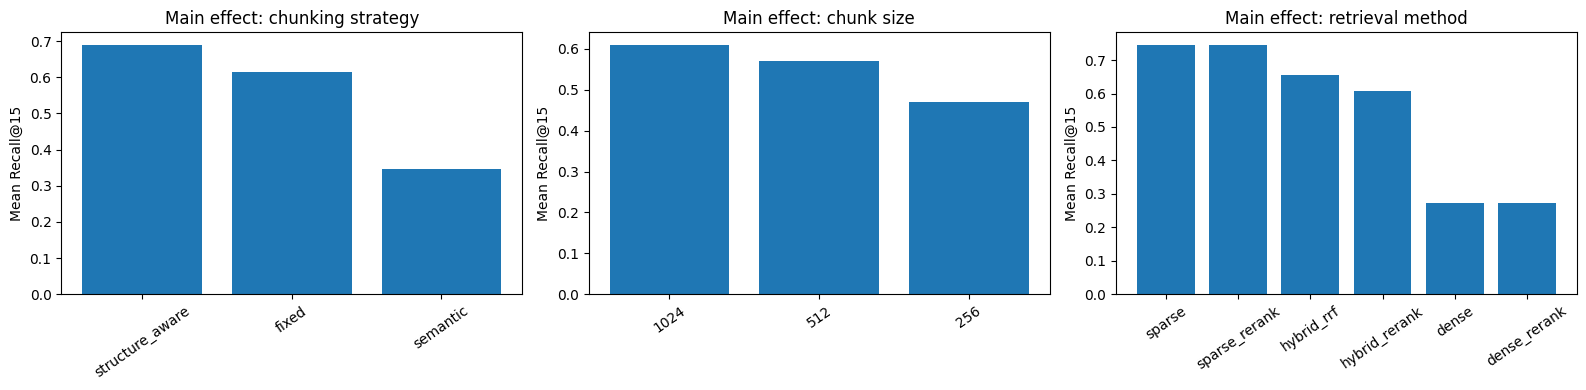

In [5]:
main_strategy = df.groupby("chunk_strategy", as_index=False)["recall@15"].mean().sort_values("recall@15", ascending=False)
main_size = df.groupby("chunk_size", as_index=False)["recall@15"].mean().sort_values("recall@15", ascending=False)
main_retrieval = df.groupby("retrieval_method", as_index=False)["recall@15"].mean().sort_values("recall@15", ascending=False)

display(main_strategy)
display(main_size)
display(main_retrieval)

fig, axes = plt.subplots(1, 3, figsize=(16, 4))
axes[0].bar(main_strategy["chunk_strategy"], main_strategy["recall@15"])
axes[0].set_title("Main effect: chunking strategy")
axes[1].bar(main_size["chunk_size"].astype(str), main_size["recall@15"])
axes[1].set_title("Main effect: chunk size")
axes[2].bar(main_retrieval["retrieval_method"], main_retrieval["recall@15"])
axes[2].set_title("Main effect: retrieval method")
for ax in axes:
    ax.set_ylabel("Mean Recall@15")
    ax.tick_params(axis="x", rotation=35)
plt.tight_layout()
plt.show()

## 6. Interaction Heatmaps

Main effects can be misleading if the factors interact: the best chunk size under one retrieval method may not be the best under another. The heatmaps below show mean Recall@15 for every pairwise combination, making interaction patterns visible.

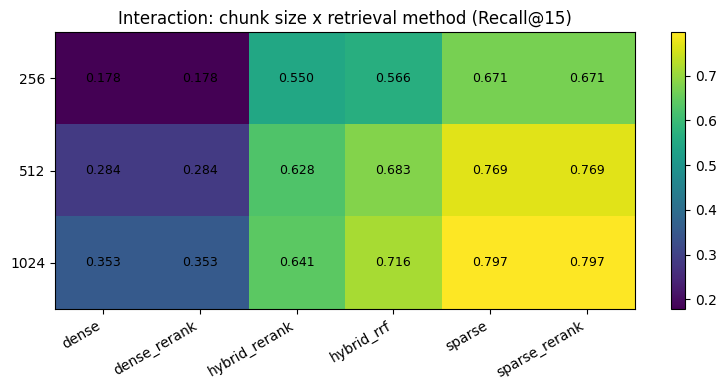

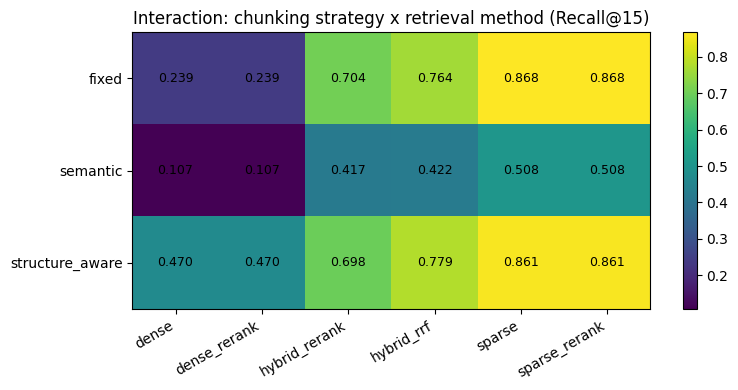

In [6]:
pivot_size_method = df.pivot_table(values="recall@15", index="chunk_size",
                                    columns="retrieval_method", aggfunc="mean")
pivot_strategy_method = df.pivot_table(values="recall@15", index="chunk_strategy",
                                       columns="retrieval_method", aggfunc="mean")

def plot_heatmap(pivot_df, title):
    fig, ax = plt.subplots(figsize=(8, 4))
    im = ax.imshow(pivot_df.values, aspect="auto")
    ax.set_xticks(range(len(pivot_df.columns)))
    ax.set_xticklabels(list(pivot_df.columns), rotation=30, ha="right")
    ax.set_yticks(range(len(pivot_df.index)))
    ax.set_yticklabels(list(pivot_df.index))
    ax.set_title(title)
    for i in range(pivot_df.shape[0]):
        for j in range(pivot_df.shape[1]):
            ax.text(j, i, f"{pivot_df.values[i, j]:.3f}",
                    ha="center", va="center", fontsize=9)
    fig.colorbar(im, ax=ax)
    plt.tight_layout()
    plt.show()

plot_heatmap(pivot_size_method, "Interaction: chunk size x retrieval method (Recall@15)")
plot_heatmap(pivot_strategy_method, "Interaction: chunking strategy x retrieval method (Recall@15)")

## 7. Winner Selection and Robustness Check

The winning configuration is selected by **Recall@15** (primary metric). As a robustness check, we also rank configurations by **Budgeted Recall@4096** which normalizes for chunk size by accumulating retrieved chunks until a 4096-token budget is reached. If the same configuration wins under both metrics, the conclusion is considered robust.

In [7]:
rank_primary = df[["config_id", "recall@15"]].sort_values("recall@15", ascending=False).reset_index(drop=True)
rank_budget = df[["config_id", "budgeted_recall@4096"]].sort_values("budgeted_recall@4096", ascending=False).reset_index(drop=True)

print("Winner by Recall@15:          ", rank_primary.iloc[0].to_dict())
print("Winner by Budgeted Recall@4096:", rank_budget.iloc[0].to_dict())

comparison = rank_primary.merge(rank_budget, on="config_id",
                                suffixes=("_primary", "_budget"))
comparison["primary_rank"] = comparison["recall@15"].rank(ascending=False, method="min").astype(int)
comparison["budget_rank"] = comparison["budgeted_recall@4096"].rank(ascending=False, method="min").astype(int)
comparison["rank_delta"] = (comparison["primary_rank"] - comparison["budget_rank"]).abs()
comparison.sort_values("primary_rank").head(15)

Winner by Recall@15:           {'config_id': 'fixed_1024_sparse', 'recall@15': 0.948937908496732}
Winner by Budgeted Recall@4096: {'config_id': 'fixed_1024_sparse', 'budgeted_recall@4096': 0.8670751633986928}


,config_id,recall@15,budgeted_recall@4096,primary_rank,budget_rank,rank_delta
0,fixed_1024_sparse,0.948938,0.867075,1,1,0
1,fixed_1024_sparse_rerank,0.948938,0.867075,1,1,0
2,structure_aware_1024_sparse,0.919526,0.831699,3,5,2
3,structure_aware_1024_sparse_rerank,0.919526,0.831699,3,5,2
4,fixed_512_sparse,0.894608,0.827451,5,7,2
5,fixed_512_sparse_rerank,0.894608,0.827451,5,7,2
6,structure_aware_512_sparse,0.889297,0.846405,7,3,4
7,structure_aware_512_sparse_rerank,0.889297,0.846405,7,3,4
8,fixed_1024_hybrid_rrf,0.858660,0.545588,9,23,14
9,structure_aware_1024_hybrid_rrf,0.846814,0.645507,10,16,6


## 8. Per-ESRS Standard Breakdown and Chunk Statistics

The winner's per-standard metrics reveal whether certain ESRS standards are harder to retrieve for. The chunk statistics show how each strategy/size combination distributes chunk lengths.

**Note on coverage**: Only 5 of 12 ESRS standards (ESRS 1, 2, E1, S1, G1) have annotated evidence passages in the current golden standard. Standards E2-E5 and S2-S4 are excluded from per-standard analysis.

In [8]:
winner_path = RQ1_RESULTS_DIR / "rq1_winner.json"
winner_payload = json.loads(winner_path.read_text(encoding="utf-8"))

print(f"Winner: {winner_payload['config_id']}")
if "evaluation_coverage" in winner_payload:
    cov = winner_payload["evaluation_coverage"]
    print(f"Evaluation coverage: {cov['n_evaluated']}/{cov['n_total']} samples "
          f"({cov['n_skipped']} skipped — no annotated evidence)")

print("\nWinner metrics:")
display(pd.DataFrame([winner_payload["metrics"]]))

print("\nPer-ESRS standard breakdown (winner):")
per_std_df = pd.DataFrame(winner_payload["per_standard_metrics"]).T
per_std_df = per_std_df.sort_values("recall@15", ascending=False)
display(per_std_df)

print("\nChunk statistics by strategy and size:")
chunk_stats_files = sorted(RQ1_RESULTS_DIR.glob("chunk_stats_*.json"))
chunk_stats_rows = [json.loads(p.read_text(encoding="utf-8")) | {"config": p.stem.replace("chunk_stats_", "")}
                    for p in chunk_stats_files]
if chunk_stats_rows:
    display(pd.DataFrame(chunk_stats_rows).sort_values("total_chunks", ascending=False))

Winner: fixed_1024_sparse
Evaluation coverage: 204/204 samples (0 skipped — no annotated evidence)

Winner metrics:


,recall@5,recall@10,recall@15,precision@5,precision@10,precision@15,ndcg@10,mrr@10,budgeted_recall@4096
0,0.868709,0.923203,0.948938,0.669608,0.578922,0.526797,0.790158,0.881378,0.867075



Per-ESRS standard breakdown (winner):


,recall@5,recall@10,recall@15,precision@5,precision@10,precision@15,ndcg@10,mrr@10,budgeted_recall@4096
ESRS E3,0.941176,0.970588,1.000000,0.611765,0.452941,0.372549,0.892455,0.949580,0.941176
ESRS E4,0.949020,1.000000,1.000000,0.905882,0.823529,0.721569,0.923801,0.960784,0.949020
ESRS 2,0.872549,0.970588,0.970588,0.647059,0.617647,0.552941,0.763289,0.791667,0.872549
ESRS S1,0.823529,0.911765,0.970588,0.505882,0.382353,0.301961,0.715927,0.774510,0.823529
ESRS 1,0.862745,0.921569,0.960784,0.788235,0.723529,0.686275,0.879226,0.901961,0.862745
ESRS E2,0.784314,0.901961,0.960784,0.658824,0.547059,0.501961,0.783997,0.901961,0.784314
ESRS S3,0.921569,0.921569,0.960784,0.705882,0.535294,0.462745,0.773857,0.852941,0.921569
ESRS G1,0.897059,0.960784,0.960784,0.717647,0.641176,0.615686,0.794892,0.941176,0.897059
ESRS S4,0.941176,0.941176,0.941176,0.658824,0.588235,0.588235,0.714446,0.911765,0.941176
ESRS E5,0.843137,0.862745,0.892157,0.435294,0.311765,0.247059,0.712446,0.805882,0.843137



Chunk statistics by strategy and size:


,total_chunks,mean_tokens,std_tokens,min_tokens,max_tokens,config
4,32572,75.144050,77.715583,1,258,semantic_256
5,30295,79.657534,113.262360,1,514,semantic_512
3,29467,80.875148,148.648872,1,1025,semantic_1024
7,12358,210.485677,76.214635,2,258,structure_aware_256
1,10445,255.767544,5.125552,36,259,fixed_256
8,7497,340.823263,186.810397,2,514,structure_aware_512
6,5337,467.872775,382.334945,2,1026,structure_aware_1024
2,5226,511.195561,13.942560,197,515,fixed_512
0,2617,1020.682461,44.835892,199,1026,fixed_1024


In [9]:
# End of RQ1 evaluation notebook.